# 04 — Gate signal σ and attention faithfulness (validation)

Two checks of what the UG-MARL model computes, both on the Jinan **validation** flow with
the five final seed-models (seed s = model trained with seed s):

1. **Is σ a useful gate signal?** Does σ rise when the detectors degrade, and is it larger
   where the learned Q-values are wrong (TD error)?
2. **Do the attention weights rank the neighbours' influence?** Perturb the neighbour with
   the highest weight, the one with the lowest, and the own observation, and measure the
   change in the network's output.

Both are associations on validation data, not causal claims; nothing is fitted or selected.
The test and held-out flows are not used. Runs 10 validation episodes (about 3 minutes).

Outputs: `docs/results/sigma_validity{,_td}.csv`, `docs/results/attention_faithfulness.csv`,
`docs/figures/ugmarl/sigma_validity.png`, `docs/figures/results/attention_faithfulness.{png,pdf}`.

In [1]:
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from trafficrl.agents import make_agent, model_label
from trafficrl.agents.ugmarl.gate import load_gate, sigma_from_q
from trafficrl.data.splits import REPO_ROOT
from trafficrl.envs.traffic_env import make_env
from trafficrl.eval.hypotheses import paired
from trafficrl.eval.runner import PRIMARY_METRIC, resolve_gate
from trafficrl.utils.config import load_config
from trafficrl.utils.plotting import BLUE, BLUE_RAMP, INK_SECONDARY, MUTED, apply_style, save_figure
from trafficrl.utils.seed import seed_everything

pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

cfg = load_config(REPO_ROOT / "configs" / "eval_ugmarl.yaml")
assert cfg["data"]["split"] == "val", "these checks use the validation split only"
TRAIN = REPO_ROOT / "results" / "train"
TUNE = REPO_ROOT / "results" / "tune"
RESULTS = REPO_ROOT / "docs" / "results"
SEEDS = [0, 1, 2, 3, 4]
TAG = "final"
variant = model_label("ugmarl", cfg)
apply_style()

## 1. σ under degraded detectors

σ of every decision in the ungated reference episodes that the gate calibration
(`scripts/calibrate_gate.py`) logged on validation: clean, noise 0.1 / 0.2, dropout 10 / 20 %.
σ's scale differs between models, so it is divided by the median clean σ of the same
seed-model before pooling.

In [2]:
CONDITIONS = ["clean", "noise0.1", "noise0.2", "drop0.1", "drop0.2"]


CONDITION_LABEL = {
    "clean": "clean",
    "noise0.1": "noise 0.1",
    "noise0.2": "noise 0.2",
    "drop0.1": "dropout 10 %",
    "drop0.2": "dropout 20 %",
}


TICK = {c: lab.replace(" ", "\n", 1) for c, lab in CONDITION_LABEL.items()}


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    """Spearman's ρ = Pearson correlation of the ranks (average ranks for ties)."""
    rx = pd.Series(x).rank().to_numpy()
    ry = pd.Series(y).rank().to_numpy()
    return float(np.corrcoef(rx, ry)[0, 1])


calib = TUNE / f"ugmarl_gate_{variant}_{TAG}" / "eval"
frames = []
for c in CONDITIONS:
    run = next(p for p in (calib / f"ref_{c}").iterdir() if p.is_dir())
    for s in SEEDS:
        d = pd.read_csv(run / f"decisions_s{s}.csv")
        frames.append(d[["sigma", "fallback"]].assign(seed=s, condition=c))
dec = pd.concat(frames, ignore_index=True)
base = dec[dec["condition"] == "clean"].groupby("seed")["sigma"].median()
dec["sigma_rel"] = dec["sigma"] / dec["seed"].map(base)
taus = {s: load_gate(TRAIN / f"{variant}_{TAG}_s{s}" / "gate.json")["tau"] for s in SEEDS}
dec["above_tau"] = dec["sigma"] > dec["seed"].map(taus)

rows = []
for c in CONDITIONS:
    g = dec[dec["condition"] == c]
    per_seed = g.groupby("seed")
    rows.append({
        "condition": c,
        "median_sigma_rel": float(g["sigma_rel"].median()),
        "mean_sigma_rel": float(g["sigma_rel"].mean()),
        "p90_sigma_rel": float(g["sigma_rel"].quantile(0.9)),
        "share_above_tau_mean": float(per_seed["above_tau"].mean().mean()),
        "share_above_tau_std": float(per_seed["above_tau"].mean().std(ddof=1)),
        "median_sigma_rel_by_seed": " ".join(f"{v:.3f}" for v in per_seed["sigma_rel"].median()),
        "n_decisions": len(g),
    })
sigma_table = pd.DataFrame(rows)
sigma_table.assign(variant=variant).to_csv(RESULTS / "sigma_validity.csv", index=False)
display(sigma_table)

,condition,median_sigma_rel,mean_sigma_rel,p90_sigma_rel,share_above_tau_mean,share_above_tau_std,median_sigma_rel_by_seed,n_decisions
0,clean,1.0000,1.0701,1.8267,0.2001,0.0002,1.000 1.000 1.000 1.000 1.000,10882
1,noise0.1,4.1811,5.6049,11.8796,0.8680,0.0337,3.914 3.213 4.597 3.771 6.339,11204
2,noise0.2,10.8205,13.7189,28.0276,0.9750,0.0092,9.556 9.138 10.617 9.170 16.704,11509
3,drop0.1,1.0192,1.0993,1.8826,0.2222,0.0109,1.039 1.026 0.993 1.038 1.010,10889
4,drop0.2,1.0591,1.1443,1.9644,0.2461,0.0248,1.112 1.060 1.011 1.053 1.064,10905


## 2. σ against the TD error

One clean, greedy, ungated validation episode per seed-model. For every transition:
|δ| = |μ(s, a) − (c·r + γ^(d/Δt) μ_target(s′, argmax μ(s′, ·)))|, the TD error of the
ensemble-mean Q, and Spearman's ρ between σ(s) and |δ|. `agent.training = False`, so
nothing is stored or learned.

In [3]:
def td_episode(cfg, seed: int, ckpt) -> pd.DataFrame:
    """σ(s) and |TD error of μ| for every transition of one clean greedy val episode."""
    seed_everything(seed, cfg.get("deterministic", True))
    env = make_env({**cfg, "seed": seed}, seed, track="light")
    agent = make_agent("ugmarl", env, {**cfg, "seed": seed})
    agent.load(ckpt)
    agent.tau, agent.training = None, False
    p = agent.params
    obs, info = env.reset()
    rows, done = [], False
    while not done:
        actions = agent.act(obs, info)
        obs, _, done, info = env.step(actions)
        for tr in info["transitions"]:
            s, s2 = agent.encoder.encode_transition(tr)
            x = torch.as_tensor(np.stack([s, s2])).unsqueeze(0)
            with torch.no_grad():
                q = agent.net(x)[0]
                qt = agent.target(x)[0]
            mu, a_next, sigma = sigma_from_q(q)
            a = agent.phase_ids.index(int(tr.action))
            boot = qt[1].mean(dim=0)[a_next[1]]
            y = float(p["reward_scale"]) * tr.reward + float(p["gamma"]) ** (
                tr.duration_s / agent.delta_t
            ) * float(boot)
            rows.append(
                {
                    "seed": seed,
                    "t": info["t"],
                    "iid": tr.iid,
                    "sigma": float(sigma[0]),
                    "td_abs": abs(float(mu[0, a]) - y),
                }
            )
    m = env.metrics()
    return pd.DataFrame(rows), m[PRIMARY_METRIC]


tds, rhos = [], []
for s in SEEDS:
    ckpt = TRAIN / f"{variant}_{TAG}_s{s}" / "checkpoints" / "best.pt"
    td, att = td_episode(cfg, s, ckpt)
    tds.append(td)
    rhos.append(spearman(td["sigma"].to_numpy(), td["td_abs"].to_numpy()))
    print(f"seed {s}: {len(td)} transitions, travel time {att:.2f} s, rho {rhos[-1]:.3f}")

td_all = pd.concat(tds, ignore_index=True)
td_all["decile"] = td_all.groupby("seed")["sigma"].transform(
    lambda v: pd.qcut(v.rank(method="first"), 10, labels=False) + 1
)
dec_tab = td_all.groupby(["seed", "decile"])["td_abs"].mean().unstack("seed")
rho_tab = pd.DataFrame({"seed": SEEDS, "spearman_sigma_vs_abs_td": rhos})
rho_tab.assign(n=[len(t) for t in tds]).to_csv(RESULTS / "sigma_validity_td.csv", index=False)
display(rho_tab)

seed 0: 2185 transitions, travel time 301.90 s, rho -0.017


seed 1: 2172 transitions, travel time 303.04 s, rho 0.024


seed 2: 2176 transitions, travel time 301.97 s, rho 0.054


seed 3: 2173 transitions, travel time 301.18 s, rho 0.002


seed 4: 2176 transitions, travel time 300.95 s, rho 0.064


,seed,spearman_sigma_vs_abs_td
0,0,-0.0172
1,1,0.0235
2,2,0.0541
3,3,0.0022
4,4,0.0636


### Figure: σ validity

(a) σ relative to the model's median clean σ under each detector condition (boxes:
quartiles, whiskers 1.5 IQR, outliers hidden; dotted line = 1). (b) Mean |TD error| per σ
decile (thin lines: seeds; thick: mean; the y axis does not start at 0).

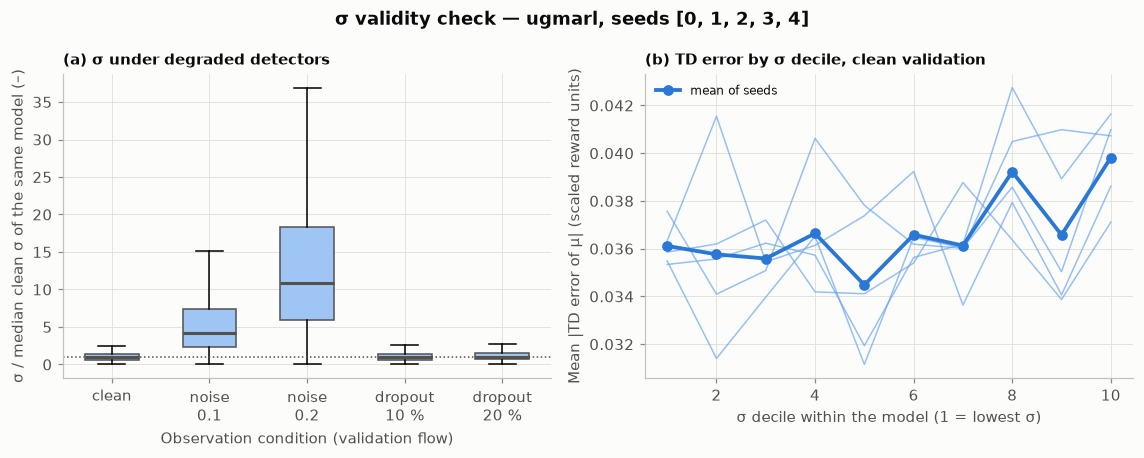

median σ / clean median: clean 1.00; noise 0.1 4.18; noise 0.2 10.82; dropout 10 % 1.02; dropout 20 % 1.06
share of decisions with σ > τ: clean 0.200; noise 0.1 0.868; noise 0.2 0.975; dropout 10 % 0.222; dropout 20 % 0.246
Spearman ρ(σ, |TD|): mean 0.03 ± 0.03; mean |TD| top decile / bottom decile = 1.10


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
data = [dec.loc[dec["condition"] == c, "sigma_rel"].to_numpy() for c in CONDITIONS]
bp = ax1.boxplot(data, showfliers=False, patch_artist=True, widths=0.55)
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE_RAMP[1], edgecolor=INK_SECONDARY)
for med in bp["medians"]:
    med.set(color=INK_SECONDARY, linewidth=2)
ax1.set_xticks(range(1, len(CONDITIONS) + 1), [TICK[c] for c in CONDITIONS])
ax1.axhline(1.0, color=INK_SECONDARY, linestyle=":", linewidth=1)
ax1.set_ylabel("σ / median clean σ of the same model (–)")
ax1.set_xlabel("Observation condition (validation flow)")
ax1.set_title("(a) σ under degraded detectors", fontsize=10)
x = dec_tab.index.to_numpy()
for s in dec_tab.columns:
    ax2.plot(x, dec_tab[s], color=BLUE_RAMP[2], linewidth=1, alpha=0.7)
ax2.plot(x, dec_tab.mean(axis=1), color=BLUE, linewidth=2.5, marker="o", label="mean of seeds")
ax2.set_xlabel("σ decile within the model (1 = lowest σ)")
ax2.set_ylabel("Mean |TD error of μ| (scaled reward units)")
ax2.set_title("(b) TD error by σ decile, clean validation", fontsize=10)
ax2.legend(frameon=False, fontsize=8)
fig.suptitle(f"σ validity check — {variant}, seeds {SEEDS}", fontweight="bold")
fig.tight_layout()
save_figure(fig, REPO_ROOT / "docs" / "figures" / "ugmarl" / "sigma_validity.png")
plt.show()

rel = dict(zip(sigma_table["condition"], sigma_table["median_sigma_rel"]))
share = dict(zip(sigma_table["condition"], sigma_table["share_above_tau_mean"]))
ratio = dec_tab.mean(axis=1)
print("median σ / clean median:", "; ".join(f"{CONDITION_LABEL[c]} {rel[c]:.2f}" for c in CONDITIONS))
print("share of decisions with σ > τ:", "; ".join(f"{CONDITION_LABEL[c]} {share[c]:.3f}" for c in CONDITIONS))
print(f"Spearman ρ(σ, |TD|): mean {np.mean(rhos):.2f} ± {np.std(rhos, ddof=1):.2f}; "
      f"mean |TD| top decile / bottom decile = {ratio.iloc[-1] / ratio.iloc[0]:.2f}")

## 3. Attention faithfulness

One clean validation episode per seed-model with UG-MARL as deployed (gate on, τ from
`gate.json`); the encoder input of every decision is recorded. Offline, one slot of each
input is perturbed and the full network is run again (attention recomputed):

* **replacement**: the slot's 44 values are swapped for the same slot's values from another
  decision of the same intersection (8 draws), so the input stays in-distribution;
* **knock-out**: the slot is masked as absent.

Reading fixed before the run: *consistent with the weights* iff mean |Δμ| is larger for the
highest-α neighbour than for the lowest-α neighbour, with a per-seed paired 95 % CI that
excludes 0.

In [5]:
SLOT_NAMES = ("self", "E", "N", "W", "S")
PERTURBATIONS = ("replacement", "knock-out")
OUTCOMES = ("abs_dmu", "max_abs_dmu", "flip", "dsigma")


def outputs(net, x: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """``μ (N, A)``, greedy action ``(N,)``, ``σ (N,)`` and ``α (N, 5)`` for inputs ``x``."""
    with torch.no_grad():
        q, alpha = net(torch.as_tensor(x).unsqueeze(0), return_attention=True)
    mu, a_star, sigma = sigma_from_q(q[0])
    if alpha is None:
        raise ValueError("the faithfulness check needs a network with attention")
    return mu.numpy(), a_star.numpy(), sigma.numpy(), alpha[0].numpy()


def donors(groups: Sequence, draws: int, rng: np.random.Generator) -> np.ndarray:
    """``(N, draws)`` row indices: for each row, other rows of the same group (intersection),
    drawn with replacement. A group with a single row has no donor (``-1``)."""
    groups = np.asarray(groups)
    out = np.full((len(groups), draws), -1, dtype=np.int64)
    for g in np.unique(groups):
        rows = np.flatnonzero(groups == g)
        if len(rows) < 2:
            continue
        pick = rng.integers(0, len(rows) - 1, size=(len(rows), draws))
        pick += pick >= np.arange(len(rows))[:, None]
        out[rows] = rows[pick]
    return out


def replace_slot(x: np.ndarray, slot: int, donor: np.ndarray) -> np.ndarray:
    """Copy of ``x`` whose ``slot`` observation comes from row ``donor`` (presence kept)."""
    out = x.copy()
    out[:, slot, :-1] = x[donor, slot, :-1]
    return out


def knock_out(x: np.ndarray, slot: int) -> np.ndarray:
    """Copy of ``x`` with ``slot`` made absent (zeros, presence flag 0)."""
    out = x.copy()
    out[:, slot, :] = 0.0
    return out


def effect(net, base: tuple, x_pert: np.ndarray) -> dict[str, np.ndarray]:
    mu, a_star, sigma, _ = base
    mu2, a2, sigma2, _ = outputs(net, x_pert)
    d = np.abs(mu2 - mu)
    rows = np.arange(len(mu))
    return {
        "abs_dmu": d[rows, a_star],
        "max_abs_dmu": d.max(axis=1),
        "flip": (a2 != a_star).astype(float),
        "dsigma": sigma2 - sigma,
    }


def slot_effects(
    net, x: np.ndarray, groups: Sequence, draws: int, rng: np.random.Generator
) -> pd.DataFrame:
    """Long frame, one row per (decision, perturbation, slot): the four outcomes (replacement:
    mean over ``draws`` donors), ``alpha`` of that slot in the unperturbed input and
    ``present``. Self is only replaced (it cannot be absent)."""
    base = outputs(net, x)
    alpha = base[3]
    present = x[:, :, -1] > 0.5
    don = donors(groups, draws, rng)
    usable = (don >= 0).all(axis=1)
    frames = []
    for slot in range(5):
        acc = {k: np.zeros(len(x)) for k in OUTCOMES}
        for r in range(draws):
            e = effect(net, base, replace_slot(x, slot, np.where(usable, don[:, r], 0)))
            for k in OUTCOMES:
                acc[k] += e[k] / draws
        frames.append(_frame("replacement", slot, acc, alpha, present & usable[:, None]))
        if slot > 0:
            frames.append(_frame("knock-out", slot, effect(net, base, knock_out(x, slot)),
                                 alpha, present))
    out = pd.concat(frames, ignore_index=True)
    return out[out["present"]].drop(columns="present").reset_index(drop=True)


def _frame(perturbation, slot, eff, alpha, present) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "decision": np.arange(len(alpha)),
            "perturbation": perturbation,
            "slot": slot,
            "alpha": alpha[:, slot],
            "present": present[:, slot],
            **eff,
        }
    )


def rank_slots(effects: pd.DataFrame) -> pd.DataFrame:
    """Keep, per decision and perturbation, the neighbour with the highest α (``hi``), the one
    with the lowest (``lo``) and the own observation (``self``). Decisions with fewer than two
    present neighbours are dropped."""
    nb = effects[effects["slot"] > 0]
    count = nb.groupby(["perturbation", "decision"])["slot"].transform("size")
    nb = nb[count >= 2]
    key = ["perturbation", "decision"]
    hi = nb.loc[nb.groupby(key)["alpha"].idxmax()].assign(rank="hi")
    lo = nb.loc[nb.groupby(key)["alpha"].idxmin()].assign(rank="lo")
    own = effects[effects["slot"] == 0]
    own = own[own["decision"].isin(set(hi["decision"]))].assign(rank="self")
    return pd.concat([hi, lo, own], ignore_index=True)


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    rx, ry = pd.Series(x).rank().to_numpy(), pd.Series(y).rank().to_numpy()
    return float(np.corrcoef(rx, ry)[0, 1])


def seed_summary(effects: pd.DataFrame) -> pd.DataFrame:
    """Per perturbation and rank (hi / lo / self): mean outcomes, mean α and n decisions; plus
    Spearman ρ between α and |Δμ| over all neighbour slots (column ``spearman``)."""
    ranked = rank_slots(effects)
    out = (
        ranked.groupby(["perturbation", "rank"], sort=False)
        .agg(n=("decision", "size"), alpha=("alpha", "mean"), **{k: (k, "mean") for k in OUTCOMES})
        .reset_index()
        .rename(columns={"rank": "slot"})
    )
    nb = effects[effects["slot"] > 0]
    rho = {p: spearman(g["alpha"].to_numpy(), g["abs_dmu"].to_numpy())
           for p, g in nb.groupby("perturbation")}
    out["spearman"] = out["perturbation"].map(rho)
    return out


def verdict(per_seed: pd.DataFrame, perturbation: str = "replacement") -> dict:
    """The reading fixed before the runs: ``consistent`` iff the per-seed paired difference of
    mean |Δμ| (highest-α − lowest-α neighbour) is > 0 with a 95 % CI that excludes 0."""
    d = per_seed[per_seed["perturbation"] == perturbation]
    piv = d.pivot(index="seed", columns="slot", values="abs_dmu").sort_index()
    diff = paired(piv["hi"].tolist(), piv["lo"].tolist())
    ok = bool(diff["mean"] > 0 and diff["ci95_low"] > 0)
    return {
        "perturbation": perturbation,
        "hi_mean": float(piv["hi"].mean()),
        "lo_mean": float(piv["lo"].mean()),
        "self_mean": float(piv["self"].mean()) if "self" in piv else float("nan"),
        "diff": diff,
        "consistent": ok,
        "text": "consistent with the weights" if ok
        else "the attention weights do not rank the neighbours' influence on Q",
    }

In [6]:
def record_episode(cfg, seed: int, ckpt: Path):
    """Play one gated greedy episode; return the encoder inputs of every decision
    ``(N, 5, obs_dim + 1)``, the intersection of each row, and the episode metrics."""
    seed_everything(seed, cfg.get("deterministic", True))
    env = make_env({**cfg, "seed": seed}, seed, track="full")
    agent = make_agent("ugmarl", env, {**cfg, "seed": seed})
    agent.load(ckpt)
    agent.tau, _ = resolve_gate({**cfg, "seed": seed}, ckpt, seed)
    agent.training = False
    pos = {iid: k for k, iid in enumerate(agent.intersection_ids)}
    states, iids = [], []
    obs, info = env.reset()
    done = False
    while not done:
        actions = agent.act(obs, info)
        x = agent.encoder.encode_all(obs)
        for iid in info["ready"]:
            states.append(x[pos[iid]])
            iids.append(iid)
        obs, _, done, info = env.step(actions)
    return agent, np.stack(states), np.asarray(iids), env.metrics()


def reference_travel_times(seeds: list[int]) -> dict[int, float]:
    """Per-seed validation travel time of gated UG-MARL."""
    ref = pd.read_csv(RESULTS / "val_phase6.csv").set_index("model")
    run = REPO_ROOT / "results" / "eval" / ref.loc["ugmarl", "eval_run"] / "metrics.csv"
    m = pd.read_csv(run).set_index("seed")[PRIMARY_METRIC]
    return {s: float(m[s]) for s in seeds}


DRAWS = 8
expected = reference_travel_times(SEEDS)
per_seed = []
for s in SEEDS:
    ckpt = TRAIN / f"ugmarl_{TAG}_s{s}" / "checkpoints" / "best.pt"
    agent, x, iids, m = record_episode(cfg, s, ckpt)
    att = float(m[PRIMARY_METRIC])
    assert abs(att - expected[s]) <= 1e-3, f"seed {s}: {att} != validation table {expected[s]}"
    eff = slot_effects(agent.net, x, iids, DRAWS, np.random.default_rng(s))
    eff.insert(0, "iid", iids[eff["decision"].to_numpy()])
    eff.insert(0, "seed", s)
    summ = seed_summary(eff)
    summ.insert(0, "seed", s)
    summ["travel_time_s"] = att
    per_seed.append(summ)
    print(f"seed {s}: {len(x)} decisions, travel time {att:.2f} s (matches the validation table)")
faith = pd.concat(per_seed, ignore_index=True)
faith.to_csv(RESULTS / "attention_faithfulness.csv", index=False)

seed 0: 2189 decisions, travel time 301.55 s (matches the validation table)


seed 1: 2177 decisions, travel time 300.93 s (matches the validation table)


seed 2: 2182 decisions, travel time 303.14 s (matches the validation table)


seed 3: 2180 decisions, travel time 303.58 s (matches the validation table)


seed 4: 2188 decisions, travel time 302.09 s (matches the validation table)


alpha  abs_dmu  max_abs_dmu    flip  dsigma  spearman
perturbation slot                                                        
knock-out    hi    0.0997   0.0418       0.0641  0.2405  0.0009    0.4744
replacement  hi    0.0997   0.0061       0.0112  0.1025 -0.0000    0.5913
knock-out    lo    0.0360   0.0238       0.0355  0.1447  0.0007    0.4744
replacement  lo    0.0360   0.0022       0.0042  0.0424 -0.0000    0.5913
             self  0.8202   0.0415       0.0842  0.8011 -0.0000    0.5913

replacement  highest-α − lowest-α |Δμ|: +0.0039 [+0.0011, +0.0066]  ->  consistent with the weights
knock-out    highest-α − lowest-α |Δμ|: +0.0181 [-0.0323, +0.0684]  ->  the attention weights do not rank the neighbours' influence on Q


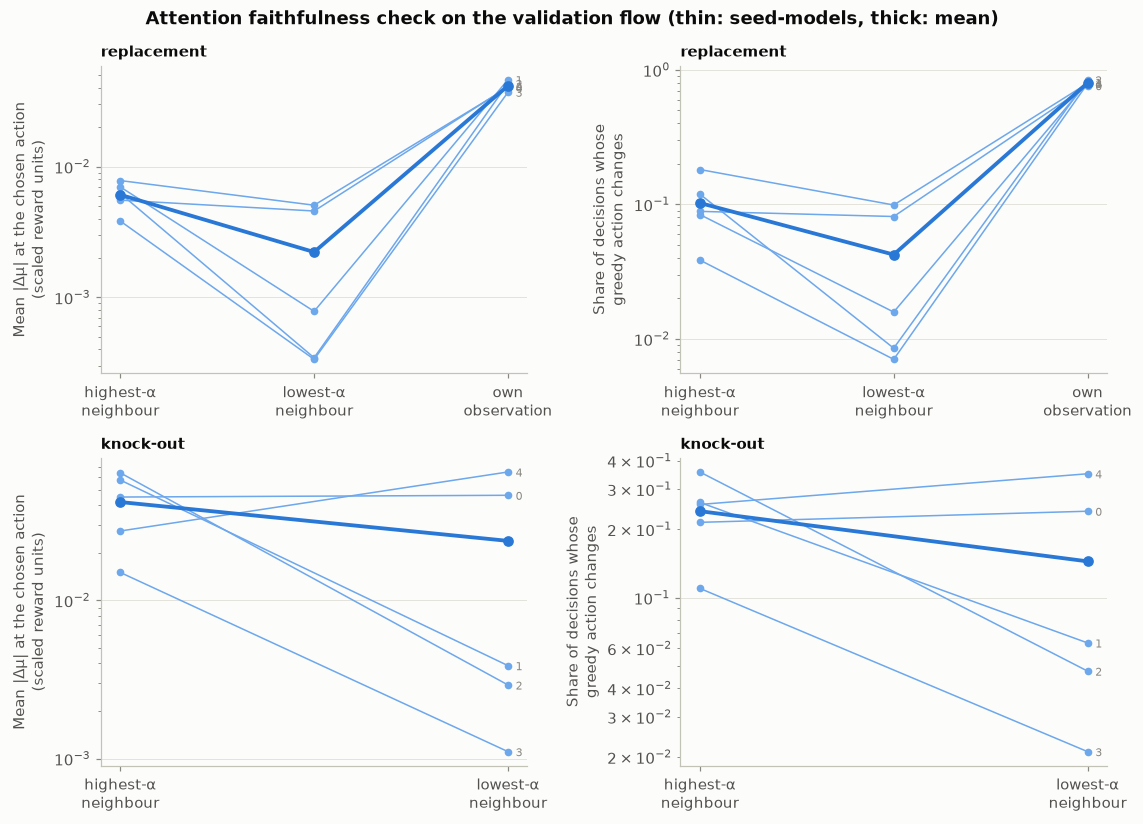

In [7]:
def save_both(fig, out, name, *_):
    """Save PNG + PDF (the report includes the PDF)."""
    fig.savefig(out / f"{name}.png")
    fig.savefig(out / f"{name}.pdf")
    return fig


def fig_faithfulness(per_seed: pd.DataFrame, out=None) -> plt.Figure:
    """``per_seed``: rows ``seed, perturbation, slot`` (hi / lo / self) with
    ``abs_dmu``, ``flip`` (docs/results/attention_faithfulness.csv)."""
    apply_style()
    found = set(per_seed["perturbation"])
    perts = [p for p in ("replacement", "knock-out") if p in found]
    fig, axes = plt.subplots(len(perts), 2, figsize=(10.5, 3.8 * len(perts)), squeeze=False)
    names = {"hi": "highest-α\nneighbour", "lo": "lowest-α\nneighbour", "self": "own\nobservation"}
    vals = []
    for r, p in enumerate(perts):
        d = per_seed[per_seed["perturbation"] == p]
        slots = [s for s in ("hi", "lo", "self") if s in set(d["slot"])]
        for ax, (col, ylabel) in zip(
            axes[r],
            [("abs_dmu", "Mean |Δμ| at the chosen action\n(scaled reward units)"),
             ("flip", "Share of decisions whose\ngreedy action changes")],
            strict=True,
        ):
            piv = d.pivot(index="seed", columns="slot", values=col)[slots]
            for s, row in piv.iterrows():
                ax.plot(range(len(slots)), row.to_numpy(), color=BLUE_RAMP[2], marker="o",
                        linewidth=1, markersize=4)
                ax.annotate(str(s), (len(slots) - 1, row.iloc[-1]), xytext=(5, -3),
                            textcoords="offset points", fontsize=7, color=MUTED)
            ax.plot(range(len(slots)), piv.mean().to_numpy(), color=BLUE, marker="o", linewidth=2.5)
            ax.set_xticks(range(len(slots)), [names[s] for s in slots])
            ax.set_ylabel(ylabel)
            ax.set_yscale("log")
            ax.set_title(f"{p}", fontsize=10)
            ax.grid(axis="x", visible=False)
            vals.append(f"{p} / {col}: " + ", ".join(
                f"{s} {piv[s].mean():.4f}" for s in slots))
    fig.suptitle("Attention faithfulness check on the validation flow "
                 "(thin: seed-models, thick: mean)", fontweight="bold")
    fig.tight_layout()
    return save_both(
        fig, out, "attention_faithfulness", "attention faithfulness check (validation)",
        "Change in the network's output when one input slot of a decision is perturbed: the "
        "neighbour with the highest attention weight, the one with the lowest, and — as an "
        "upper reference — the intersection's own observation. Replacement = the slot's 44 "
        "values are swapped for the same slot's values from another decision of the same "
        "intersection in the same episode (8 draws); knock-out = the slot is masked as "
        "absent. One clean validation episode per seed-model, decisions with ≥ 2 neighbours; "
        "log y axes. An association check on validation data.",
        "; ".join(vals) + ".",
    )


summary = faith.groupby(["perturbation", "slot"], sort=False)[
    ["alpha", "abs_dmu", "max_abs_dmu", "flip", "dsigma", "spearman"]].mean()
display(summary.round(4))
for p in PERTURBATIONS:
    v = verdict(faith, p)
    print(f"{p:12s} highest-α − lowest-α |Δμ|: {v['diff']['mean']:+.4f} "
          f"[{v['diff']['ci95_low']:+.4f}, {v['diff']['ci95_high']:+.4f}]  ->  {v['text']}")
fig = fig_faithfulness(faith, REPO_ROOT / "docs" / "figures" / "results")
plt.show()

**Reading (rule fixed before the run).** *Replacement — consistent with the weights:* swapping
the observation of the highest-α neighbour moves the Q-value of the chosen action by 0.0061,
of the lowest-α neighbour by 0.0022 (paired difference 0.0039, CI [0.0011, 0.0066]); the
greedy action changes in 10 % vs 4 % of decisions; Spearman ρ between α and the effect is
positive in every seed (0.16–0.89). So the weights do rank the neighbours' influence, as an
association. *Size:* swapping the intersection's **own** observation moves Q by 0.0415 and
changes the action in 80 % of decisions — about seven times the strongest neighbour. The
policy is mostly local, which fits the 0.82 self-weight and H3. *Knock-out* (masking a
neighbour as absent) gives larger effects but no reliable ranking (CI includes 0, two seeds
with ρ near 0): removing a slot also changes the softmax over the rest and is an input the
network only ever saw at the network edge. The attention maps can be shown as "where the
encoder looks, in an order that matches influence", with the caveat that the influence is small.